In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import squareform
import scipy.cluster.hierarchy as sch
pd.set_option('display.max_columns', 100)
import weighting_methods as wm

In [11]:
def plotCorrMatrix(path,corr,labels = None,title = None):
    if labels is None:
        labels = []

    plt.pcolor(corr)
    plt.colorbar()
    plt.yticks(np.arange(0.5,corr.shape[0]+0.5), labels)
    plt.xticks(np.arange(0.5,corr.shape[0]+0.5), labels,rotation=90)
    if title is not None:
        plt.title(title)
    if path is not None:
        plt.savefig(path)  
        plt.close() 
    # plt.clf()
    plt.show()

def plotDendrogram(link, labels=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))
    dendro = sch.dendrogram(link, labels=labels, ax=ax, leaf_rotation=90)
    dendro_idx = np.arange(0, len(dendro["ivl"]))
    return dendro, dendro_idx, ax

def perf_stats(daily, t=None, rf=0.0, ppy=252):
    r    = daily.pct_change().dropna()
    ex   = r - rf / ppy
    yrs  = (len(daily) - 1) / ppy                    # periods, not calendar days
    cagr = (daily.iloc[-1] / daily.iloc[0]) ** (1 / yrs) - 1

    peak = daily.cummax()
    dd   = daily / peak - 1
    uw   = dd < 0
    tuw  = uw.groupby((~uw).cumsum()).cumsum()       # consecutive bars underwater

    v, hi = daily.values, peak.values
    tr  = int(dd.values.argmin())                    # trough position
    pk  = np.flatnonzero(v[:tr + 1] >= hi[tr])[-1]   # last bar at the high before trough
    rc  = np.flatnonzero(v[tr:] >= hi[tr])
    rec = tr + rc[0] if len(rc) else None
    end = rec if rec is not None else len(v) - 1
    # print(f"Max DD: peak {daily.index[pk]} -> trough {daily.index[tr]} -> "
    #       + (f"recovered {daily.index[rec]}" if rec is not None else "NOT recovered"))

    out = {
        'Total return (%)':          100 * (daily.iloc[-1] / daily.iloc[0] - 1),
        'CAGR (%)':                  100 * cagr,
        'Ann. vol (%)':              100 * r.std() * np.sqrt(ppy),
        'Sharpe':                    ex.mean() / ex.std() * np.sqrt(ppy),
        'Sortino':                   ex.mean() / np.sqrt((np.minimum(ex, 0) ** 2).mean()) * np.sqrt(ppy),
        'Max DD (%)':                100 * dd.min(),
        'Calmar':                    cagr / abs(dd.min()),
        'Max DD duration (bars)':    end - pk,
        'Longest underwater (bars)': tuw.max(),
        'Time underwater (%)':       100 * uw.mean(),
    }

    if t is not None:
        pnl = t['pnl']
        win, loss = pnl[pnl > 0], pnl[pnl < 0]
        n_open = (t.groupby('entry_idx').size()
                    .sub(t.groupby('exit_idx').size(), fill_value=0)
                    .reindex(daily.index, fill_value=0).cumsum())
        out.update({
            'Trades':                 len(t),
            'Win rate (%)':           100 * (pnl > 0).mean(),
            'Profit factor':          win.sum() / -loss.sum(),
            'Payoff (avg W / avg L)': win.mean() / -loss.mean(),
            'Expectancy (R)':         t['R'].mean(),
            'Time in market (%)':     100 * (n_open > 0).mean(),
            'Peak leverage (x)':      t['lev_entry'].max(),
        })

    return pd.Series(out)

,target_SR,realized_SR
H1,0.41,0.57
H2,0.57,1.05
W1,0.50,0.48
W2,0.61,0.59
W3,0.78,1.22
W4,0.85,0.70
Z1,0.60,0.69


,H1,H2,W1,W2,W3,W4,Z1
H1,1.00,0.94,-0.00,0.25,-0.08,0.14,0.04
H2,0.94,1.00,-0.01,0.24,-0.07,0.13,0.05
W1,-0.00,-0.01,1.00,0.35,0.68,0.47,0.01
W2,0.25,0.24,0.35,1.00,0.48,0.42,-0.20
W3,-0.08,-0.07,0.68,0.48,1.00,0.54,-0.09
W4,0.14,0.13,0.47,0.42,0.54,1.00,-0.19
Z1,0.04,0.05,0.01,-0.20,-0.09,-0.19,1.00


,Total return (%),CAGR (%),Ann. vol (%),Sharpe,Sortino,Max DD (%),Calmar,Max DD duration (bars),Longest underwater (bars),Time underwater (%)
H1,160.239362,10.036634,16.893854,0.650686,0.944857,-31.436408,0.319268,410.0,435.0,92.423641
H2,316.773774,15.342680,13.646245,1.114466,1.658896,-26.041261,0.589168,514.0,514.0,88.813963
W1,107.437879,7.569415,15.124182,0.558048,0.821429,-26.101189,0.290003,866.0,865.0,94.684649
W2,171.785239,10.515346,16.988192,0.673500,0.999560,-28.039679,0.375017,265.0,439.0,93.375645
W3,591.145801,21.326863,15.883884,1.296791,1.998320,-36.011283,0.592227,394.0,393.0,88.694962
W4,221.952517,12.403331,16.672922,0.784706,1.165568,-27.536836,0.450427,603.0,602.0,93.732646
Z1,272.008386,14.039492,19.067892,0.784346,1.172905,-24.499530,0.573051,708.0,707.0,93.375645


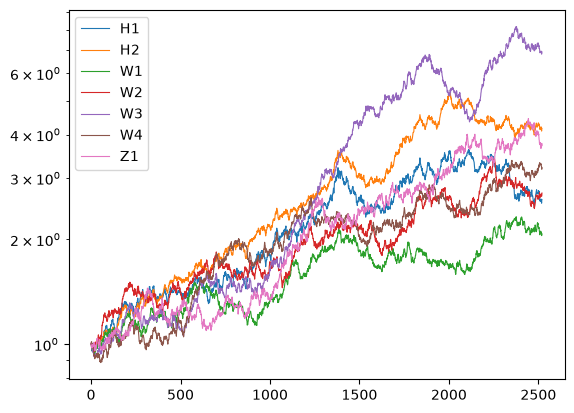

In [12]:
NObs = 1260*2
EXACT = False
# np.random.seed(12345)

def make_groups(n, frac_hi=0.2, frac_zero=0.2):
    n_h = max(2, round(n * frac_hi)); n_z = max(1, round(n * frac_zero))
    return [('H', n_h, (0.85, 0.95)), ('W', n - n_h - n_z, (0.30, 0.40)), ('Z', n_z, (0.0, 0.0))]

def build_universe(groups):
    names, gid, lo, hi = [], [], [], []
    for g, (p, k, (a, b)) in enumerate(groups):
        names += [f'{p}{j}' for j in range(1, k + 1)]
        gid += [g] * k; lo += [a] * k; hi += [b] * k
    return names, np.array(gid), np.sqrt(lo), np.sqrt(hi)

GROUPS = make_groups(7)
names, gid, b_lo, b_hi = build_universe(GROUPS)
n, n_groups = len(names), len(GROUPS)

def sample_corr(noise_df=50):
    """Group factor structure, optionally perturbed by finite-sample (Wishart) noise.
    Smaller noise_df = messier matrix; must be > n + 1. None = clean."""
    b = np.random.uniform(b_lo, b_hi)
    B = np.zeros((n, n_groups)); B[np.arange(n), gid] = b
    C = B @ B.T
    np.fill_diagonal(C, 1.0)
    rng = np.random.default_rng(np.random.randint(2**31))   # always drawn, so noise on/off
    if noise_df:                                             # doesn't shift later random draws
        assert noise_df > n + 1, 'noise_df must exceed n + 1'
        X = rng.standard_normal((noise_df, n)) @ np.linalg.cholesky(C).T
        C = np.corrcoef(X, rowvar=False)
    return C

# 1) target correlation matrix
C = sample_corr()
L = np.linalg.cholesky(C)

# 2) correlated standard-normal shocks
Z = np.random.randn(NObs, n)
if EXACT:
    m  = Z.mean(0)
    Ls = np.linalg.cholesky(np.cov(Z, rowvar=False))
    Z  = (Z - m) @ np.linalg.inv(Ls).T + m # sample cov = I exactly, random means kept
eps = Z @ L.T

# 3) returns: random positive edge per strategy, time-varying but always > 0
sigma = np.random.uniform(0.008, 0.015, n)      # ~13-19% annual vol
SR    = np.random.uniform(0.4, 1.0, n)          # target annual Sharpe (the "edge")
alpha = SR * sigma / np.sqrt(252)               # mean daily drift

# edge strength wanders: log-OU multiplier, always positive, mean 1
hl, edge_vol = 126, 0.53                        # half-life in days, dispersion of the edge
phi   = 0.5 ** (1 / hl)
shock = np.random.randn(NObs, n) * edge_vol * np.sqrt(1 - phi**2)
x = np.empty((NObs, n))
x[0] = edge_vol * np.random.randn(n)            # start in the stationary distribution
for t in range(1, NObs):
    x[t] = phi * x[t-1] + shock[t]
mult  = np.exp(x - edge_vol**2 / 2)             # E[mult] = 1, so average drift = alpha
drift = alpha * mult

r = drift + sigma * eps

# target vs realized Sharpe
realized_SR = r.mean(0) / r.std(0) * np.sqrt(252)
display(pd.DataFrame({'target_SR': SR, 'realized_SR': realized_SR}, index=names).round(2))

# 4) equity curves
y = np.vstack([np.zeros(n), np.cumsum(r, axis=0)])
equity = pd.DataFrame(np.exp(y), columns=names)
equity.plot(logy=True, lw=0.8)

display(pd.DataFrame(r, columns=names).corr().round(2))
stats = pd.DataFrame({k: perf_stats(equity[k], ppy=252) for k in equity}).T
display(stats)

,Total return (%),CAGR (%),Ann. vol (%),Sharpe,Sortino,Max DD (%),Calmar,Max DD duration (bars),Longest underwater (bars),Time underwater (%),ann_turnover
EW,200.064234,12.985784,8.928642,1.412354,2.143302,-8.126388,1.597977,110.0,339.0,87.880123,0.331624
EW_filtered,168.490973,11.598628,9.578974,1.193722,1.796921,-10.113687,1.146825,147.0,293.0,88.497135,1.648389
Equity,190.858755,12.595294,8.918978,1.374954,2.082098,-8.489060,1.483709,147.0,340.0,87.968268,0.329759
InvVol,200.816484,13.017221,9.002863,1.404541,2.129541,-8.241610,1.579451,304.0,340.0,88.012340,0.348686
HRP,204.481430,13.169391,8.674172,1.469934,2.240633,-7.964952,1.653417,288.0,287.0,87.527545,0.462310
HRP_rmt,207.349036,13.287324,8.682717,1.480572,2.259237,-7.871718,1.687983,109.0,278.0,87.527545,0.572112
RP,206.397702,13.248308,8.682732,1.476602,2.254261,-8.191217,1.617380,110.0,292.0,87.395328,0.373462
RP_rmt,207.400097,13.289415,8.637155,1.488138,2.278290,-8.209907,1.618705,110.0,285.0,86.998678,0.378322
MinVar,240.419993,14.581046,8.455882,1.652342,2.560386,-7.296666,1.998316,129.0,268.0,86.073160,0.665863
MinVar_rmt,247.444575,14.841377,8.680307,1.637979,2.567781,-7.487558,1.982139,75.0,211.0,85.764654,0.558313


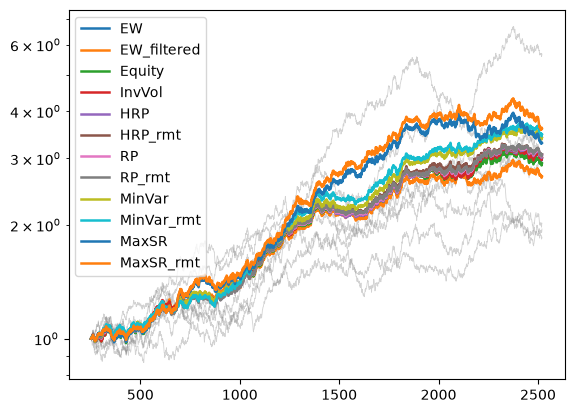

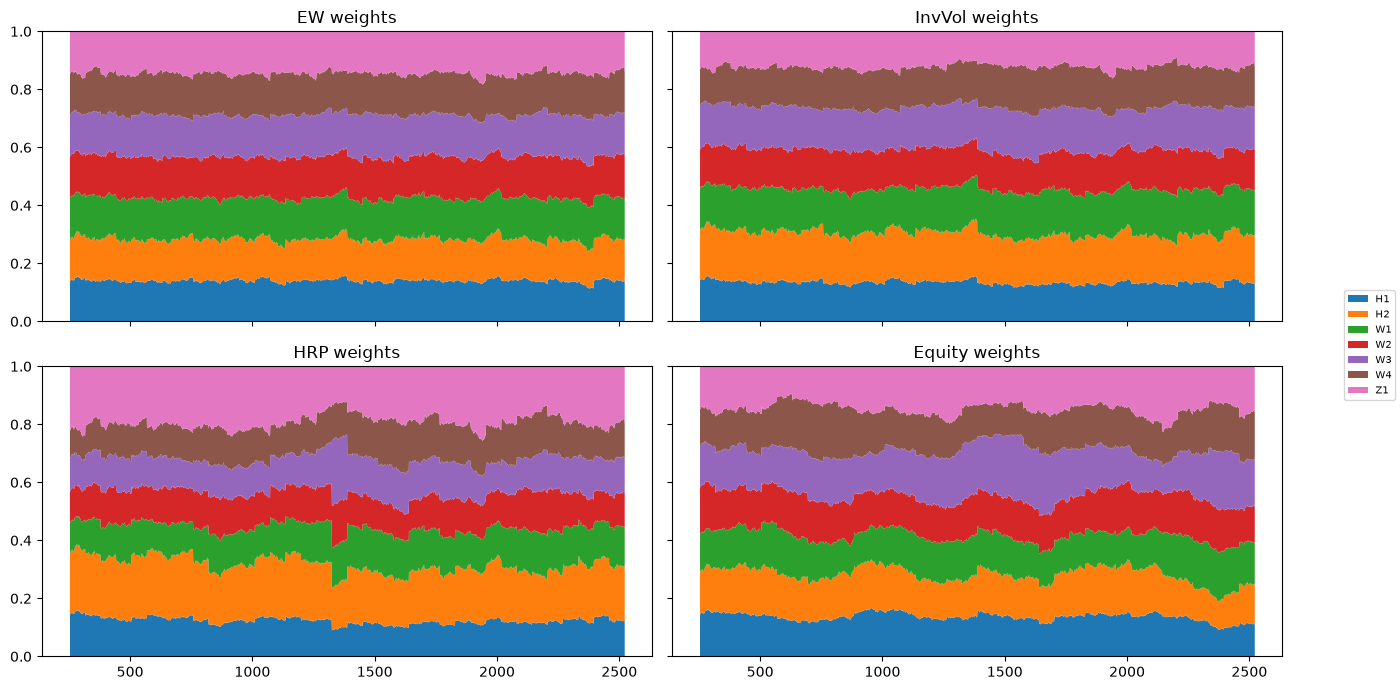

In [13]:
# --- rolling backtest ---
def backtest(equity, weight_fn, lookback=63, rebal=21, cost_bps=0):
    R = equity.pct_change().dropna()
    X = R.values
    T, N = X.shape
    port = np.full(T, np.nan)
    W = np.full((T, N), np.nan)
    turnover = np.zeros(T)
    w = None

    for t in range(T):
        if w is not None:                              # earn day-t return on weights held from t-1
            g = w @ X[t]
            port[t] = g
            w = w * (1 + X[t]) / (1 + g)               # weights drift between rebalances
        if t >= lookback - 1 and (t - lookback + 1) % rebal == 0:
                    target = weight_fn(R.iloc[t - lookback + 1 : t + 1])
                    if isinstance(target, pd.Series):              # align labelled weights to column order
                        target = target.reindex(R.columns).values
                    turnover[t] = np.abs(target - (0 if w is None else w)).sum()
                    w = target
        if w is not None:
            W[t] = w

    cost = np.r_[0, turnover[:-1]] * cost_bps / 1e4    # charged on the day after the trade
    p = pd.Series(port - cost, index=R.index).dropna()
    eq = pd.concat([pd.Series(1.0, index=[R.index[lookback - 1]]), (1 + p).cumprod()])
    W = pd.DataFrame(W, index=R.index, columns=R.columns).dropna()
    ann_turnover = turnover.sum() / (len(p) / 252)
    return eq, W, ann_turnover


# --- run ---
methods = {
    'EW':     wm.equal_weight,
    'EW_filtered': lambda R: wm.ew_filtered(R, window=252),
    'Equity' : wm.trailing_growth_weight,
    'InvVol': wm.inverse_vol,
    'HRP':    wm.hrp_weights,
    'HRP_rmt': lambda R: wm.hrp_weights(R, rmt=True),
    'RP': wm.risk_parity,
    'RP_rmt': lambda R: wm.risk_parity(R, rmt=True),
    'MinVar': wm.min_variance,
    'MinVar_rmt': lambda R: wm.min_variance(R, rmt=True),
    'MaxSR':  wm.max_sharpe,
    'MaxSR_rmt':  lambda R: wm.max_sharpe(R, rmt=True),
}
lookback, rebal, cost_bps = 252, 63, 0

res = {k: backtest(equity, f, lookback, rebal, cost_bps) for k, f in methods.items()}
port_eq = pd.DataFrame({k: v[0] for k, v in res.items()})

ax = equity.loc[port_eq.index[0]:].div(equity.loc[port_eq.index[0]]).plot(
    logy=True, lw=0.6, alpha=0.35, legend=False, color='grey')
port_eq.plot(ax=ax, lw=1.8, logy=True)

port_stats = pd.DataFrame({k: perf_stats(port_eq[k], ppy=252) for k in port_eq}).T
port_stats['ann_turnover'] = {k: v[2] for k, v in res.items()}
display(port_stats)

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey=True)
for ax, k in zip(axes.flat, ['EW', 'InvVol', 'HRP', 'Equity']):
    res[k][1].plot.area(ax=ax, lw=0, legend=False, title=f'{k} weights')
    ax.set_ylim(0, 1)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center right', fontsize=7)
plt.tight_layout(rect=[0, 0, 0.93, 1])     # leave room on the right for the legend
plt.show()

In [14]:
import matplotlib.pyplot as plt

def simulate(seed=None, NObs=1260*2,
             hl=126, edge_vol=0.5,                                  # time-varying edge (as before)
             p_stress_in=1/750, p_stress_out=1/40,                   # regime switching
             stress_corr_lift=0.6, vol_mult_stress=1.75, stress_SR=-1.5,
             p_death_annual=0.01, death_stress_mult=3.0, post_death_SR=0.0,
             return_info=False):
    np.random.seed(seed)
    sq = np.sqrt(252)

    # calm correlation structure (as before)
    # calm correlation structure, built from GROUPS
    C = sample_corr()
    L = np.linalg.cholesky(C)
    k = stress_corr_lift
    C_s = (1 - k) * C + k                          # stress corr: every pair pulled toward 1                      # stress corr: every pair pulled toward 1

    # 1) regimes: 2-state Markov chain (calm / stress)
    stress = np.zeros(NObs, bool)
    stress[0] = np.random.rand() < p_stress_in / (p_stress_in + p_stress_out)
    u = np.random.rand(NObs)
    for t in range(1, NObs):
        stress[t] = (u[t] >= p_stress_out) if stress[t-1] else (u[t] < p_stress_in)

    # 2) shocks: in stress, mix in a common factor -> correlations jump, never fall
    eps = np.random.randn(NObs, n) @ L.T
    f   = np.random.randn(NObs, 1)
    eps = np.where(stress[:, None], np.sqrt(1 - k) * eps + np.sqrt(k) * f, eps)

    # 3) time-varying positive edge (as before)
    sigma = np.random.uniform(0.008, 0.015, n)
    SR    = np.random.uniform(0.7, 1.5, n)
    alpha = SR * sigma / sq
    phi   = 0.5 ** (1 / hl)
    shock = np.random.randn(NObs, n) * edge_vol * np.sqrt(1 - phi**2)
    x = np.empty((NObs, n)); x[0] = edge_vol * np.random.randn(n)
    for t in range(1, NObs):
        x[t] = phi * x[t-1] + shock[t]
    edge = alpha * np.exp(x - edge_vol**2 / 2)

    # 4) strategy death: permanent, more likely during stress
    h    = 1 - (1 - p_death_annual) ** (1 / 252)
    h_t  = np.where(stress, h * death_stress_mult, h)
    dead = np.maximum.accumulate(np.random.rand(NObs, n) < h_t[:, None], axis=0)

    # 5) returns: stress overrides drift and scales vol
    vol_t = sigma * np.where(stress, vol_mult_stress, 1.0)[:, None]
    drift = np.where(dead, post_death_SR * sigma / sq, edge)
    drift = np.where(stress[:, None], stress_SR * vol_t / sq, drift)
    r = drift + vol_t * eps

    y = np.vstack([np.zeros(n), np.cumsum(r, axis=0)])
    equity = pd.DataFrame(np.exp(y), columns=names)
    if not return_info:
        return equity
    death_day = np.where(dead.any(0), dead.argmax(0), -1)
    return equity, dict(stress=stress, dead=dead, death_day=death_day, returns=r,
                        C=C, C_stress=C_s, SR=SR, sigma=sigma)

# --- 2) one iteration: all methods on the same universe ---
def run_one(seed):
    equity = simulate(seed)
    rows = []
    for k, f in methods.items():
        eq, W, to = backtest(equity, f, lookback, rebal, cost_bps)
        d = dict(perf_stats(eq, ppy=252))
        d.update(method=k, iter=seed, ann_turnover=to)
        rows.append(d)
    return rows



In [15]:

from tqdm.auto import tqdm

N, PARALLEL = 5000, True
if PARALLEL:
    from joblib import Parallel, delayed
    gen = Parallel(n_jobs=-1, return_as='generator_unordered')(
        delayed(run_one)(s) for s in range(N))
    out = list(tqdm(gen, total=N, desc='Simulations'))
else:
    out = [run_one(s) for s in tqdm(range(N), desc='Simulations')]

mc = pd.DataFrame([row for rows in out for row in rows])
metrics = [c for c in mc.columns if c not in ('method', 'iter')]
order = list(methods)
print(metrics)



Simulations: 100%|██████████| 5000/5000 [38:41<00:00,  2.15it/s]  


['Total return (%)', 'CAGR (%)', 'Ann. vol (%)', 'Sharpe', 'Sortino', 'Max DD (%)', 'Calmar', 'Max DD duration (bars)', 'Longest underwater (bars)', 'Time underwater (%)', 'ann_turnover']


Total return (%)                                                \
                        mean      std      p05      p50       p95      IQR   
method                                                                       
EW                   418.259  258.816  108.983  363.000   900.610  291.002   
EW_filtered          473.019  292.410  121.194  417.145  1015.602  332.280   
Equity               461.684  296.017  118.591  398.690  1013.158  324.340   
InvVol               392.451  239.355  105.481  342.799   843.798  273.041   
HRP                  369.246  222.634   99.133  325.317   778.645  253.721   
HRP_rmt              370.711  224.881  100.559  325.087   795.289  257.604   
RP                   392.791  237.230  104.904  345.086   838.279  273.614   
RP_rmt               393.064  238.191  105.371  346.562   837.055  274.793   
MinVar               337.580  217.171   83.411  296.118   730.431  239.193   
MinVar_rmt           332.715  219.770   76.850  287.894   740.228  246.346   
MaxSR                661.562  506.920  150.091  546.326  1594.400  491.864   
MaxSR_rmt            674.543  538.898  147.688  552.878  1634.930  498.053   

            CAGR (%)                                        Ann. vol (%)  \
                mean    std     p05     p50     p95     IQR         mean   
method                                                                     
EW            18.731  6.301   8.534  18.564  29.164   8.092       10.968   
EW_filtered   19.986  6.584   9.221  20.030  30.734   8.471       11.925   
Equity        19.685  6.593   9.078  19.546  30.703   8.488       11.147   
InvVol        18.132  6.083   8.331  17.978  28.328   7.932       10.622   
HRP           17.556  5.911   7.954  17.451  27.312   7.680       10.203   
HRP_rmt       17.581  5.952   8.039  17.444  27.577   7.783       10.213   
RP            18.161  6.036   8.297  18.045  28.244   7.928       10.365   
RP_rmt        18.163  6.050   8.324  18.089  28.225   7.963       10.365   
MinVar        16.574  6.022   6.972  16.527  26.516   7.759        9.710   
MinVar_rmt    16.376  6.146   6.540  16.255  26.681   8.078        9.931   
MaxSR         23.168  8.043  10.722  23.041  36.949  10.313       13.200   
MaxSR_rmt     23.296  8.217  10.603  23.179  37.309  10.390       13.475   

                                                  Sharpe                       \
               std     p05     p50     p95    IQR   mean    std    p05    p50   
method                                                                          
EW           1.534   8.654  10.848  13.711  2.027  1.656  0.572  0.730  1.640   
EW_filtered  1.724   9.377  11.775  15.015  2.303  1.629  0.564  0.715  1.624   
Equity       1.531   8.824  11.041  13.879  2.051  1.699  0.574  0.767  1.685   
InvVol       1.508   8.373  10.494  13.318  1.990  1.658  0.573  0.722  1.643   
HRP          1.499   7.973  10.073  12.886  1.975  1.675  0.584  0.727  1.660   
HRP_rmt      1.494   8.008  10.067  12.886  1.973  1.675  0.585  0.731  1.655   
RP           1.545   8.065  10.235  13.131  2.042  1.704  0.593  0.746  1.688   
RP_rmt       1.550   8.066  10.242  13.147  2.033  1.704  0.594  0.747  1.688   
MinVar       1.462   7.544   9.585  12.315  1.926  1.668  0.622  0.683  1.640   
MinVar_rmt   1.462   7.787   9.793  12.551  1.916  1.612  0.611  0.637  1.598   
MaxSR        2.193   9.928  13.023  17.151  2.979  1.693  0.603  0.738  1.674   
MaxSR_rmt    2.244  10.068  13.323  17.476  3.028  1.667  0.596  0.731  1.648   

                          Sortino                                     \
               p95    IQR    mean    std    p05    p50    p95    IQR   
method                                                                 
EW           2.618  0.751   2.531  0.966  1.034  2.465  4.210  1.274   
EW_filtered  2.573  0.758   2.497  0.949  1.026  2.454  4.134  1.267   
Equity       2.671  0.767   2.604  0.974  1.079  2.549  4.302  1.285   
InvVol       2.615  0.754   2.535  0.968  1.016  2.4

,mean_diff_vs_EW,t_stat,win_rate_vs_EW
method,,,
EW_filtered,54.760,40.423,0.724
Equity,43.425,51.498,0.879
InvVol,-25.808,-50.578,0.195
HRP,-49.013,-42.436,0.242
HRP_rmt,-47.548,-37.428,0.273
RP,-25.468,-36.573,0.289
RP_rmt,-25.195,-31.919,0.314
MinVar,-80.679,-42.815,0.245
MinVar_rmt,-85.544,-41.160,0.253


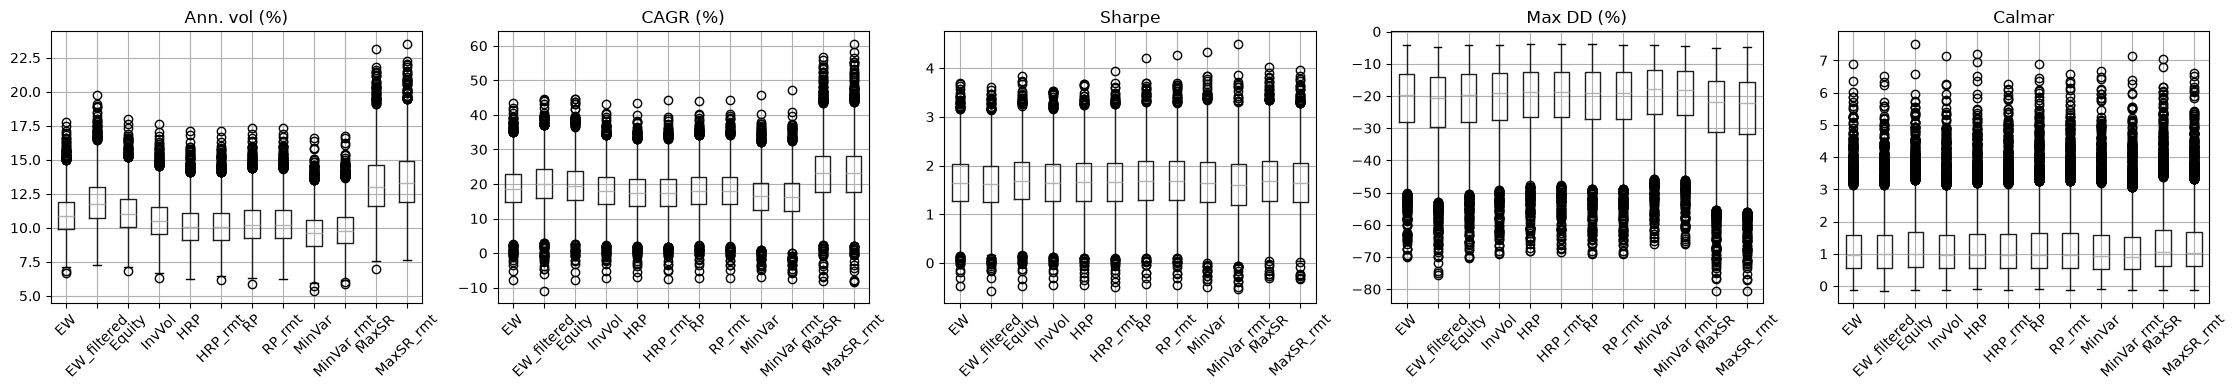

In [16]:

# --- 4) distribution summary per method ---
def q(p): return (f'p{int(p*100):02d}', lambda x: x.quantile(p))
iqr = ('IQR', lambda x: x.quantile(.75) - x.quantile(.25))
summary = mc.groupby('method')[metrics].agg(['mean', 'std', q(.05), q(.5), q(.95),iqr]).loc[order]
display(summary.round(3))


# --- 5) boxplots ---
plot_metrics = ['Ann. vol (%)','CAGR (%)','Sharpe','Max DD (%)','Calmar']          # pick the perf_stats keys you care about
fig, axes = plt.subplots(1, len(plot_metrics), figsize=(4.5 * len(plot_metrics), 4))
for ax, m in zip(axes, plot_metrics):
    mc.pivot(index='iter', columns='method', values=m)[order].boxplot(ax=ax, rot=45)
    ax.set_title(m)
plt.tight_layout()


# --- 6) paired comparison vs EW (same universe each iteration) ---
metric = metrics[0]                                    # set to your Sharpe key from perf_stats
P = mc.pivot(index='iter', columns='method', values=metric)[order]
D = P.sub(P['EW'], axis=0).drop(columns='EW')
display(pd.DataFrame({
    'mean_diff_vs_EW': D.mean(),
    't_stat':          D.mean() / D.std() * np.sqrt(len(D)),
    'win_rate_vs_EW':  (D > 0).mean(),
}).round(3))

In [17]:
summary.to_pickle('summary_RMT_7_noise_50.pickle')
mc.to_pickle('mc_RMT_7_noise_50.pickle')

Seed was: 10156
{'H1': np.int64(-1), 'H2': np.int64(-1), 'W1': np.int64(-1), 'W2': np.int64(-1), 'W3': np.int64(-1), 'W4': np.int64(-1), 'Z1': np.int64(-1)}


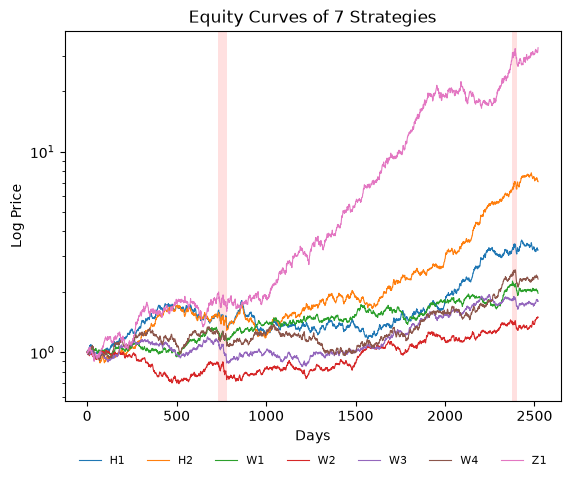

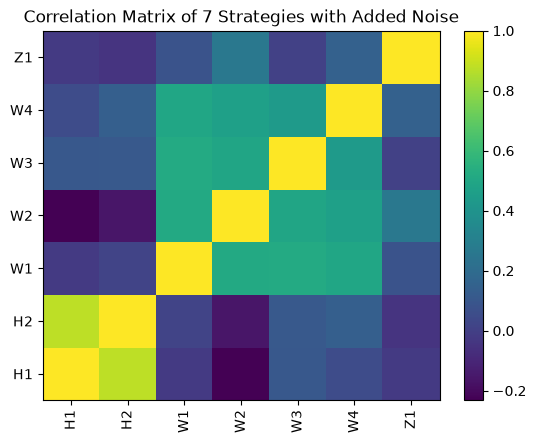

,Total return (%),CAGR (%),Ann. vol (%),Sharpe,Sortino,Max DD (%),Calmar,Max DD duration (bars),Longest underwater (bars),Time underwater (%),ann_turnover
EW,270.826247,15.675441,9.262100,1.618978,2.406722,-17.309729,0.905586,308.0,307.0,85.279859,0.351048
EW_filtered,240.357437,14.578707,10.025921,1.407925,2.068985,-24.928432,0.584822,826.0,825.0,85.985015,1.515669
Equity,316.974209,17.192824,9.447402,1.727081,2.593377,-17.139589,1.003106,308.0,307.0,84.310269,0.352028
InvVol,216.065780,13.639897,9.130739,1.446401,2.132090,-17.230204,0.791627,310.0,309.0,87.086822,0.353800
HRP,229.257660,14.157379,9.085200,1.503225,2.225239,-17.447810,0.811413,393.0,392.0,86.293521,0.461308
HRP_rmt,272.639021,15.738135,9.160523,1.641819,2.447359,-17.553822,0.896565,388.0,387.0,84.750992,0.544355
RP,264.356901,15.449455,9.116430,1.621913,2.411992,-17.468929,0.884396,308.0,307.0,85.103570,0.405807
RP_rmt,289.939643,16.323210,9.150751,1.698613,2.538562,-17.491061,0.933232,308.0,307.0,84.574703,0.437864
MinVar,233.502947,14.319992,8.968278,1.537519,2.284134,-17.437599,0.821214,394.0,393.0,86.690172,0.903143
MinVar_rmt,264.125791,15.441317,9.182813,1.610058,2.418912,-17.433752,0.885714,392.0,391.0,85.896871,0.944963


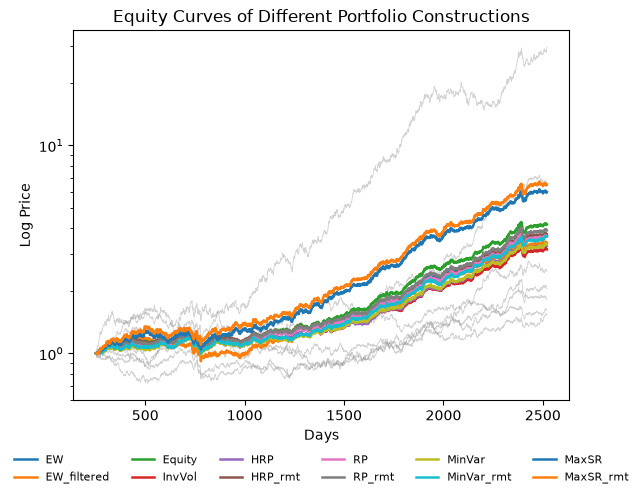

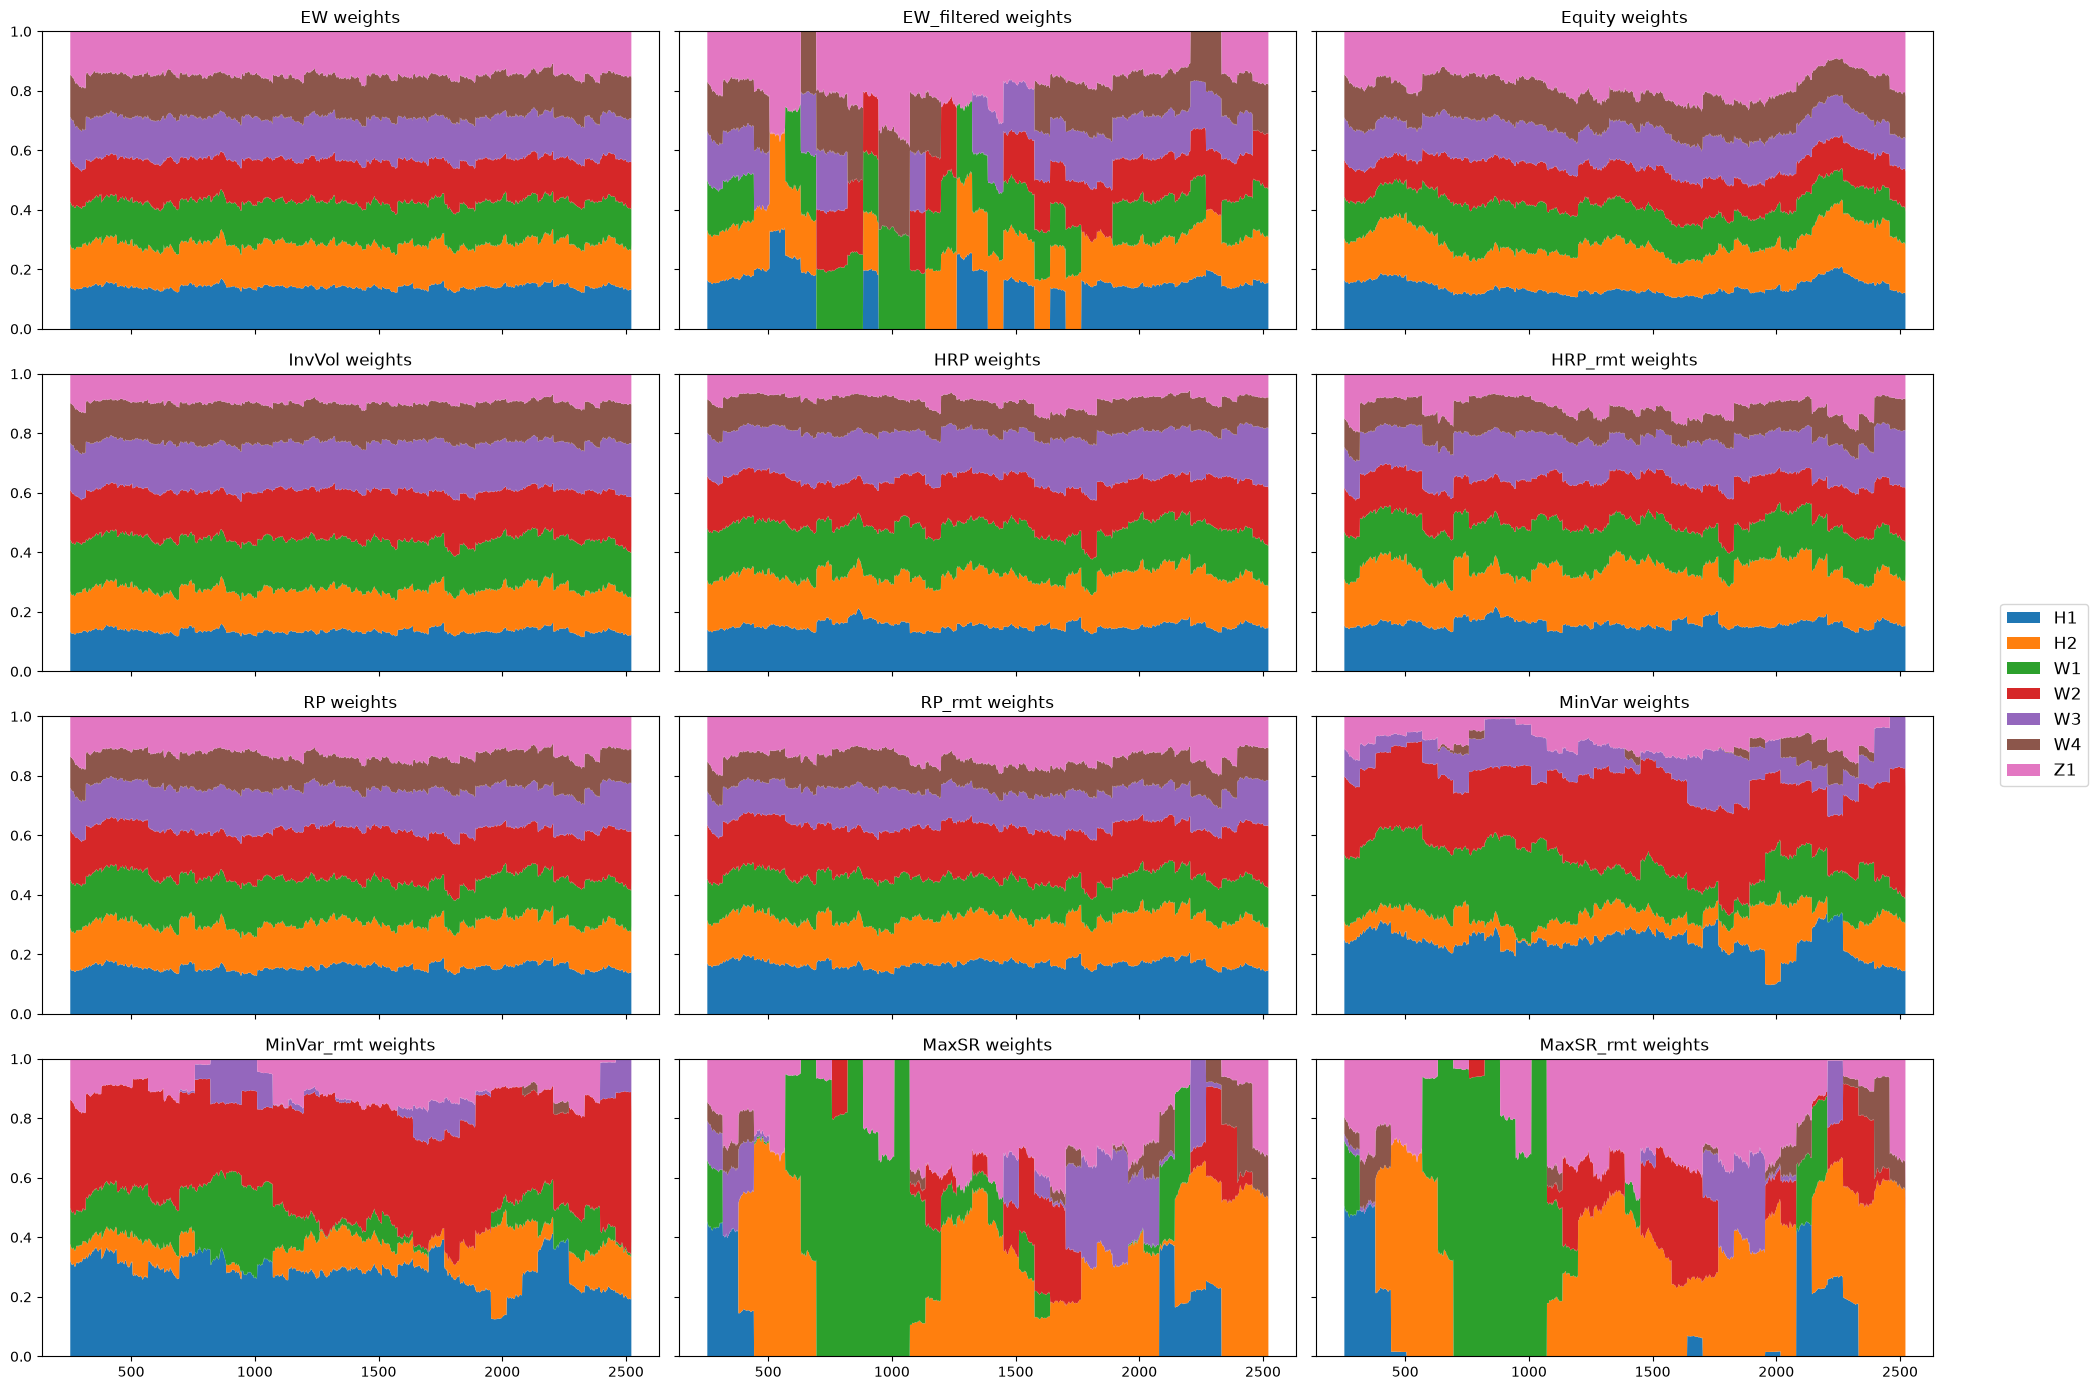

In [18]:
import random
seed = random.randrange(100000)
rng = random.Random(seed)
print("Seed was:", seed)

eq, info = simulate(seed = 45865,return_info=True)
logy = True
ax = eq.plot(logy=logy, lw=0.8)
for t in np.flatnonzero(np.diff(info['stress'].astype(int)) == 1):
    end = t + 1 + np.argmin(info['stress'][t+1:]) if not info['stress'][t+1:].all() else len(info['stress'])
    ax.axvspan(t + 1, end + 1, color='red', alpha=0.12, lw=0)
print(dict(zip(names, info['death_day'])))   # -1 = survived
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=10, frameon=False, fontsize=8)
plt.xlabel('Days')
plt.ylabel('Log Price')
plt.title(f'Equity Curves of {len(eq.columns)} Strategies')
plt.show()
''''''

x = eq.pct_change().dropna()
cov, corr = x.cov(), x.corr()
plotCorrMatrix(None,corr, labels=corr.columns,title = f'Correlation Matrix of {len(eq.columns)} Strategies with Added Noise')
dist = wm.correlDist(corr)
dist_vals = dist.values.copy()
np.fill_diagonal(dist_vals, 0.0)
link = sch.linkage(squareform(dist_vals, checks=False), 'single')
sortIx = wm.getQuasiDiag(link)
sortIx = corr.index[sortIx].tolist()
df0 = corr.loc[sortIx, sortIx]
# plotCorrMatrix(None,df0, labels=df0.columns,title = 'Quasi-Diagonalised Correlation Matrix of 25 Stocks in 5 Different Sectors')
''''''

lookback, rebal, cost_bps = 252, 63, 0

res = {k: backtest(eq, f, lookback, rebal, cost_bps) for k, f in methods.items()}
port_eq = pd.DataFrame({k: v[0] for k, v in res.items()})

ax = eq.loc[port_eq.index[0]:].div(eq.loc[port_eq.index[0]]).plot(
    logy=logy, lw=0.6, alpha=0.35, legend=False, color='grey')
ax = port_eq.plot(ax=ax, lw=1.8, logy=logy)
handles, labels = ax.get_legend_handles_labels()
k = port_eq.shape[1]                                  # number of portfolio lines
ax.legend(handles[-k:], labels[-k:], loc='upper center', bbox_to_anchor=(0.5, -0.12),
          ncol=6, frameon=False, fontsize=8)
plt.xlabel('Days')
plt.ylabel('Log Price')
plt.title('Equity Curves of Different Portfolio Constructions')
''''''
port_stats = pd.DataFrame({k: perf_stats(port_eq[k], ppy=252) for k in port_eq}).T
port_stats['ann_turnover'] = {k: v[2] for k, v in res.items()}
display(port_stats)

fig, axes = plt.subplots(4, 3, figsize=(21, 14), sharex=True, sharey=True)
for ax, k in zip(axes.flat, ['EW','EW_filtered','Equity','InvVol','HRP','HRP_rmt','RP','RP_rmt','MinVar','MinVar_rmt','MaxSR','MaxSR_rmt']):
    res[k][1].plot.area(ax=ax, lw=0, legend=False, title=f'{k} weights')
    ax.set_ylim(0, 1)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center right', fontsize=12)
plt.tight_layout(rect=[0, 0, 0.93, 1])     # leave room on the right for the legend
# plt.suptitle('Portfolio Weights of All Strategies')
plt.show()